# Graph Convolutional Networks for Molecules
## Predicting ¹³C NMR chemical shifts directly from molecular structure

*Original tutorial by Cantarella (Haote) Li, 2/12/2021. Revised and expanded for current Google Colab, November 2026.*

---

**What you will build.** A neural network that reads a molecule as a *graph* (atoms = nodes, bonds = edges) and predicts the ¹³C NMR chemical shift (in ppm) of every carbon atom. You can compare your results with those of Jonas & Kuhn, *J. Cheminform.* **11**, 50 (2019).

**You do not need prior knowledge of PyTorch or PyTorch Geometric.** Every step is explained in a text cell before the code, and the code itself is commented line by line.

### Learning goals

After working through this notebook you will be able to:

1. Explain what a **molecular graph** is and how a molecule becomes **node features** plus an **edge index**.
2. Explain what a **graph convolution** does, and verify one by hand against `GCNConv`.
3. Build a **PyTorch Geometric** data pipeline in which many molecules are batched into one large disconnected graph.
4. Train a deep GCN with **residual connections**, **batch normalisation** and a **masked loss** (so that only ¹³C atoms are trained on).
5. Evaluate a regression model honestly: separate **train / validation / test** sets, **MAE / RMSE / R²**, parity plot, and a look at the **worst predictions**.
6. Go from a **SMILES string** to a predicted ¹³C spectrum.

### Roadmap

| § | Section | What happens |
|---|---------|--------------|
| 0 | Background | NMR, graphs, graph convolution in a nutshell |
| 1 | Setup | Install libraries, imports, seeds, GPU check, settings |
| 2 | Data | Load and inspect the NMR dataset |
| 3 | Featurisation | RDKit molecule → 47 numbers per atom + bond list |
| 4 | Graph dataset | Batching, train/validation/test split |
| 5 | Model | GCN primer (by hand), then the full architecture |
| 6 | Training | Masked MSE loss, Adam, checkpointing, learning curves |
| 7 | Evaluation | Metrics, parity plot, worst molecules |
| 8 | Bonus | Your own molecule from a SMILES string |
| 9 | Wrap-up | Exercises, limitations, change log, references |

### How to run this notebook in Colab

* **Runtime → Change runtime type → GPU** (a T4 is fine). The model is small, so CPU also works, only slower.
* Then **Runtime → Run all**, *or* step through cell by cell (recommended the first time).
* The dataset file is **not** included. You will be asked to upload it in §2.
* Tip: set `EPOCHS = 3` in §1.3 for a quick end-to-end test before the real training run.

## 0. Background (read this once, refer back later)

### 0.1 What is a ¹³C chemical shift?

In NMR spectroscopy each ¹³C nucleus resonates at a frequency that depends on its **local electronic environment**. We report this as the *chemical shift* δ in parts per million (**ppm**) relative to a reference compound (TMS). Roughly:

| Carbon type | Typical δ (ppm) |
|---|---|
| sp³ C–H, alkyl | 0 – 50 |
| C attached to O or N | 50 – 90 |
| alkene / aromatic | 100 – 150 |
| carbonyl (C=O) | 160 – 220 |

The environment is determined mostly by **which atoms are nearby and how they are bonded**: hybridisation, electronegative neighbours, ring membership, conjugation. That is exactly the kind of information a molecular graph encodes, and it is why graph neural networks work well for this task. (The classical, non-neural analogue is the HOSE-code lookup, which also describes an atom by its spheres of neighbours.)

### 0.2 A molecule is a graph

* **Nodes** = atoms. Each node carries a **feature vector** (atomic number, hybridisation, charge, ...).
* **Edges** = bonds. We store them as an `edge_index` of shape `[2, number_of_edges]`: row 0 lists source atoms, row 1 lists target atoms. Bonds are undirected, so each bond appears **twice** (A→B and B→A). For `CC` (ethane skeleton) that is `[[0, 1], [1, 0]]`.

### 0.3 What does a graph convolution do?

A graph convolution layer updates every atom's feature vector by **mixing in its neighbours' vectors**. For the Kipf & Welling GCN layer used here:

$$H^{(l+1)} \;=\; \sigma\!\Big(\tilde D^{-1/2}\,\tilde A\,\tilde D^{-1/2}\; H^{(l)}\, W^{(l)}\Big),\qquad \tilde A = A + I$$

* $A$ is the adjacency matrix and $I$ adds a **self-loop**, so an atom keeps part of its own information.
* $\tilde D$ is the diagonal degree matrix of $\tilde A$; the $\tilde D^{-1/2}\cdots\tilde D^{-1/2}$ factors normalise so that atoms with many neighbours do not simply produce larger numbers.
* $W^{(l)}$ is a **learned** weight matrix, shared by all atoms, and $\sigma$ is a non-linearity (ReLU).

**Stacking layers widens the field of view.** After one layer an atom "knows" its direct neighbours; after *k* layers it knows everything within *k* bonds. Our network has 6 graph-convolution layers, so each carbon sees its 6-bond neighbourhood, a good match for the local nature of chemical shifts. You will verify the formula numerically in §5.1.

### 0.4 Glossary

| Term | Meaning |
|---|---|
| **SMILES** | A text string describing a molecule, e.g. `CCO` = ethanol. |
| **Feature** | One number describing a node (e.g. "is aromatic"). |
| **Batch** | A group of molecules processed together in one gradient step. |
| **Epoch** | One full pass over the training set. |
| **Loss** | The number we minimise; here the mean squared error (MSE) in ppm². |
| **MAE** | Mean absolute error, the average |prediction − experiment| in ppm. Easier to interpret than MSE. |
| **Overfitting** | Training error keeps falling while error on unseen data stops improving or rises. |

## 1. Setup

### 1.1 Install libraries

We need two packages that Colab does not ship with:

* **RDKit** reads molecules, perceives atom properties and draws structures.
* **PyTorch Geometric (`torch_geometric`)** adds graph layers and graph data loaders on top of PyTorch (which Colab already provides, together with NumPy, pandas, Matplotlib and tqdm).

> The original notebook also installed `kora`, `mendeleev`, `torch-scatter` and `torch-sparse` from wheel files built for PyTorch 1.7 / CUDA 10.1. Those are not needed (and no longer installable) on current Colab; see the change log in §9.

If Colab shows a *"restart session"* message after this cell, do **Runtime → Restart session** once and then continue from the next cell (do not re-run the installer).

In [ ]:
# "%pip" installs into the *running* notebook kernel (preferred over "!pip" in notebooks).
# -q = quiet. Both publish pre-built wheels, so installation is usually quick.
%pip install -q rdkit torch_geometric

### 1.2 Imports, random seeds and device

We import everything once, here, so the rest of the notebook can focus on ideas.

* **Seeds** make runs repeatable (same initial weights, same shuffling). Results can still differ slightly between GPU types.
* **Device**: PyTorch tensors live either on the CPU or on the GPU (`cuda`). The model and each batch must be on the *same* device.

In [ ]:
import os, sys, time, math, random, pickle, shutil, urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm                     # progress bars

import torch
import torch.nn as nn
import torch_geometric
from torch_geometric.data import Data          # one graph (= one molecule)
from torch_geometric.loader import DataLoader  # batches many graphs together
from torch_geometric.nn import GCNConv         # the graph-convolution layer

import rdkit
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem, Draw, rdPartialCharges
from rdkit.Chem.Draw import IPythonConsole                # makes Mol objects render as pictures

RDLogger.DisableLog('rdApp.*')                 # RDKit prints many harmless warnings; silence them
try:
    IPythonConsole.drawOptions.bondLineWidth = 1.8   # slightly thicker bonds in drawings
except AttributeError:
    pass

SEED = 19999
def set_seed(seed=SEED):
    """Make Python, NumPy and PyTorch random number generators repeatable."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed()

IN_COLAB = "google.colab" in sys.modules
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Python {sys.version.split()[0]} | torch {torch.__version__} | "
      f"torch_geometric {torch_geometric.__version__} | RDKit {rdkit.__version__}")
print(f"pandas {pd.__version__} | numpy {np.__version__}")
if device.type == "cuda":
    print("Device: GPU ->", torch.cuda.get_device_name(0))
else:
    print("Device: CPU. Training will work but be slower. In Colab use "
          "Runtime > Change runtime type > GPU.")

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Python 3.13.16 | torch 2.14.1+cu130 | torch_geometric 2.8.1 | RDKit 2026.09.1
pandas 2.2.3 | numpy 2.4.6
Device: GPU -> Tesla T4


### 1.3 Settings you may want to change

All the "knobs" of the tutorial live in this one cell. Change a value, then re-run this cell *and everything after it that depends on it* (the data pipeline in §4 and the model in §5 read these values).

| Setting | Meaning |
|---|---|
| `EPOCHS` | How many passes over the training data. Use **3** for a smoke test, 100 for a real run. |
| `BATCH_SIZE` | Molecules per gradient step. |
| `LEARNING_RATE` | Step size of the Adam optimiser. |
| `VAL_FRACTION` | Share of training molecules held out as a **validation set** (used to pick the best epoch). |
| `HIDDEN` | Width of the hidden layers (number of numbers describing each atom internally). |
| `REQUIRE_COMPLETE_SPECTRA` | Keep only molecules for which **every** carbon has an experimental shift (the original tutorial's behaviour). |

In [ ]:
#@title 1.3 Settings { display-mode: "form" }
EPOCHS = 100 #@param {type:"integer"}
BATCH_SIZE = 256 #@param {type:"integer"}
LEARNING_RATE = 1e-3 #@param {type:"number"}
VAL_FRACTION = 0.1 #@param {type:"number"}
HIDDEN = 128 #@param {type:"integer"}
REQUIRE_COMPLETE_SPECTRA = True #@param {type:"boolean"}

print(dict(EPOCHS=EPOCHS, BATCH_SIZE=BATCH_SIZE, LEARNING_RATE=LEARNING_RATE,
           VAL_FRACTION=VAL_FRACTION, HIDDEN=HIDDEN,
           REQUIRE_COMPLETE_SPECTRA=REQUIRE_COMPLETE_SPECTRA))

{'EPOCHS': 100, 'BATCH_SIZE': 256, 'LEARNING_RATE': 0.001, 'VAL_FRACTION': 0.1, 'HIDDEN': 128, 'REQUIRE_COMPLETE_SPECTRA': True}


## 2. Loading the data

We use the experimental ¹³C data prepared for *Rapid prediction of NMR spectral properties with quantified uncertainty* (Jonas & Kuhn, J. Cheminform. 2019, 11:50), derived from the NMRShiftDB.

**About the dataset**

* About **15,000+ unique molecules** with experimental ¹³C spectra.
* Some molecules have several spectra, so there are **20,000+ entries** (rows) in total.
* The data is already split into a **training** and a **test** table.
* Molecules are stored as RDKit `Mol` objects **with explicit hydrogens and a 3-D conformer**.

### 2.1 Provide the file

The file is named

`graph_conv_many_nuc_pipeline.data.13C.nmrshiftdb_hconfspcl_nmrshiftdb.aromatic.64.0.mol_dict.pickle`

and is **not bundled with this notebook**. Choose one option in the next cell:

| `data_source` | What it does |
|---|---|
| `upload` | Opens a file-picker; select the pickle from your computer (it is lost when the Colab runtime resets). |
| `google_drive` | Mounts your Drive and reads the file from `drive_folder` (best if you will come back to this notebook). |
| `url` | Downloads from `data_url` if you host the file somewhere. |

> ⚠️ **Security note.** Python *pickle* files can execute arbitrary code when loaded. Only load a pickle that you obtained from a source you trust.

In [ ]:
#@title 2.1 Provide the dataset { display-mode: "form" }
data_source = "upload" #@param ["upload", "google_drive", "url"]
drive_folder = "/content/drive/MyDrive/GCN_NMR" #@param {type:"string"}
data_url = "" #@param {type:"string"}

DATA_FILENAME = ("graph_conv_many_nuc_pipeline.data.13C.nmrshiftdb_hconfspcl_nmrshiftdb."
                 "aromatic.64.0.mol_dict.pickle")
data_path = DATA_FILENAME            # default: a copy in the current working directory

if os.path.exists(DATA_FILENAME):
    print("Found the dataset in the working directory, nothing to do.")

elif data_source == "upload":
    if not IN_COLAB:
        raise RuntimeError("Not running in Colab: place the pickle next to the notebook and re-run.")
    from google.colab import files
    print("Select the dataset pickle in the dialog below ...")
    uploaded = files.upload()
    if not uploaded:
        raise FileNotFoundError("No file was uploaded.")
    uploaded_name = next(iter(uploaded))
    if uploaded_name != DATA_FILENAME:         # Colab appends "(1)" etc. on repeated uploads
        os.replace(uploaded_name, DATA_FILENAME)

elif data_source == "google_drive":
    from google.colab import drive
    drive.mount("/content/drive")
    data_path = os.path.join(drive_folder, DATA_FILENAME)
    if not os.path.exists(data_path):
        raise FileNotFoundError(f"Not found: {data_path}\nCheck 'drive_folder' above.")

elif data_source == "url":
    if not data_url:
        raise ValueError("Please enter a data_url.")
    print("Downloading ...")
    urllib.request.urlretrieve(data_url, DATA_FILENAME)

print(f"Dataset path: {data_path}  ({os.path.getsize(data_path) / 1e6:.1f} MB)")

Select the dataset pickle in the dialog below ...


Saving graph_conv_many_nuc_pipeline.data.13C.nmrshiftdb_hconfspcl_nmrshiftdb.aromatic.64.0.mol_dict.pickle to graph_conv_many_nuc_pipeline.data.13C.nmrshiftdb_hconfspcl_nmrshiftdb.aromatic.64.0.mol_dict.pickle
Dataset path: graph_conv_many_nuc_pipeline.data.13C.nmrshiftdb_hconfspcl_nmrshiftdb.aromatic.64.0.mol_dict.pickle  (30.7 MB)


The next cell reads the pickle. We try `pandas.read_pickle` first, because it knows how to read tables that were pickled with *older* pandas versions, and fall back to the plain `pickle` module.

The result is a dictionary. The tutorial uses:

* `train_df`, `test_df`: pandas tables, one row per spectrum, with (at least) the columns
  * `rdmol`: the molecule as an RDKit `Mol` (with explicit H atoms and a conformer),
  * `value`: a list whose first element is a **dictionary `{atom_index: shift_in_ppm}`**, with entries only for carbons that were assigned in that spectrum.
* `MAX_N`, `spectra_config`, `tgt_nucs`: bookkeeping from the authors' original data-preparation pipeline. We print them for completeness, but this tutorial does not need them.

In [ ]:
def load_dataset(path):
    """Load the pickled dictionary, tolerating tables pickled by older pandas versions."""
    try:
        return pd.read_pickle(path)
    except Exception as err:
        print("pandas.read_pickle failed:", repr(err))
        print("Falling back to the plain pickle module ...")
        with open(path, "rb") as fh:
            return pickle.load(fh)

data = load_dataset(data_path)

# Fail early, with a readable message, if the file is not what we expect.
missing = [k for k in ("train_df", "test_df") if k not in data]
if missing:
    raise KeyError(f"Dataset is missing {missing}. Keys found: {list(data.keys())}")

train_df, test_df = data["train_df"], data["test_df"]
print("Keys in the pickle   :", list(data.keys()))
print("Training table       :", train_df.shape, "| columns:", list(train_df.columns))
print("Test table           :", test_df.shape)
print("MAX_N, tgt_nucs      :", data.get("MAX_N"), data.get("tgt_nucs"))
print("spectra_config       :", data.get("spectra_config"))

Keys in the pickle   : ['train_df', 'test_df', 'MAX_N', 'spectra_config', 'tgt_nucs']
Training table       : (21523, 4) | columns: ['molecule_id', 'rdmol', 'spectra_ids', 'value']
Test table           : (5390, 4)
MAX_N, tgt_nucs      : 64 ['13C']
spectra_config       : [('13C', 'dataset.named/spectra.nmrshiftdb_13C.feather')]


### 2.2 Inspecting the data

Before any machine learning, **look at your data**. First we unpack the two columns into plain Python lists:

* `*_mols`: list of RDKit molecules,
* `*_shifts`: list of dictionaries `{carbon atom index: experimental shift}` (the *targets*).

Note that some spectra are **incomplete**: not every carbon of the molecule has an assigned shift.

In [ ]:
def get_mols_and_shifts(df):
    """Return (list of RDKit molecules, list of {atom_index: shift_ppm} dicts) from a table."""
    mols = list(df["rdmol"])
    shifts = [dict(v[0]) for v in df["value"]]   # value[0] holds the {atom index: shift} dict
    return mols, shifts

train_mols, train_shifts = get_mols_and_shifts(train_df)
test_mols,  test_shifts  = get_mols_and_shifts(test_df)
print(f"{len(train_mols):,} training spectra, {len(test_mols):,} test spectra")

21,523 training spectra, 5,390 test spectra


Let's draw one molecule and write the experimental shift next to each assigned carbon. Change `entry` to browse the dataset.

(The molecule object contains explicit hydrogens; we remove them *only for drawing*, after attaching the labels, so that the picture is readable.)

Experimental 13C shifts {carbon atom index: ppm}:
{0: 77.8, 1: 123.1, 2: 124.1, 3: 111.5, 4: 129.5, 5: 143.2, 6: 109.8, 9: 154.5, 12: 70.0, 13: 84.7, 15: 70.2, 16: 80.2, 18: 61.7}


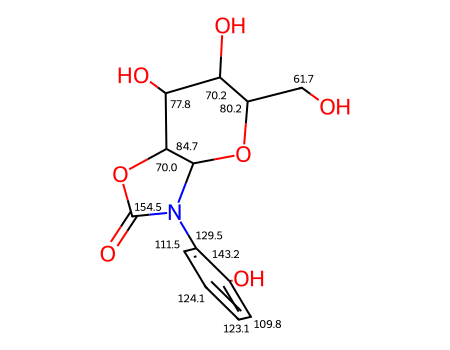

In [ ]:
def draw_with_notes(mol, notes):
    """Return a hydrogen-free copy of `mol` with a text label on selected atoms.

    notes: {atom_index: text}. Indices refer to the ORIGINAL molecule (labels are attached
    before the hydrogens are removed, so they follow the atoms).
    """
    m = Chem.Mol(mol)                                   # work on a copy
    for idx, text in notes.items():
        m.GetAtomWithIdx(int(idx)).SetProp("atomNote", text)
    return Chem.RemoveHs(m)

entry = 13   # <- try other numbers!
mol, shifts = train_mols[entry], train_shifts[entry]
print("Experimental 13C shifts {carbon atom index: ppm}:")
print({k: round(v, 1) for k, v in sorted(shifts.items())})
Draw.MolToImage(draw_with_notes(mol, {k: f"{v:.1f}" for k, v in shifts.items()}), size=(450, 350))

Next, some **summary statistics of the training set**: how the targets are distributed, how large the molecules are, how many spectra are fully assigned, and whether hydrogens are explicit. A few minutes here often save hours of debugging later.

Labelled carbons: 213,564 | shift range -14.2 to 333.8 ppm | mean 98.1 +/- 51.3
Spectra where EVERY carbon is assigned: 80.0%
Molecules with explicit hydrogens: 99.8%


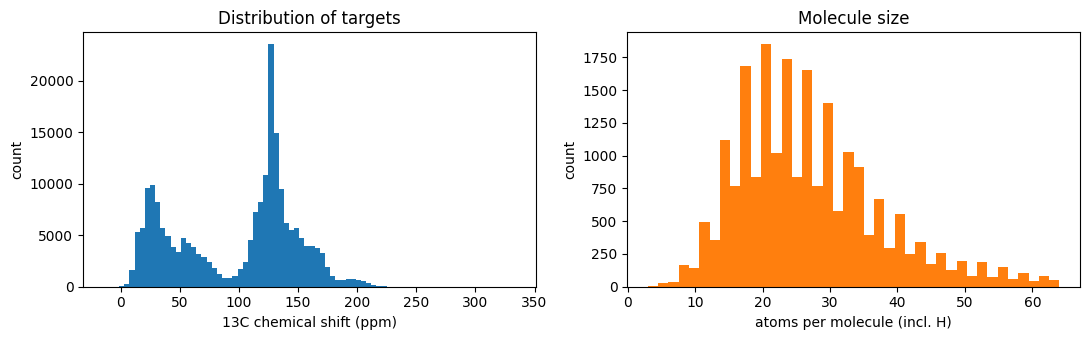

In [ ]:
# --- Dataset statistics: always worth a look before modelling ---------------------------
all_shifts = np.array([s for d in train_shifts for s in d.values()])
n_atoms    = np.array([m.GetNumAtoms() for m in train_mols])
n_carbons  = np.array([sum(a.GetAtomicNum() == 6 for a in m.GetAtoms()) for m in train_mols])
n_labelled = np.array([len(d) for d in train_shifts])
has_H      = np.mean([any(a.GetAtomicNum() == 1 for a in m.GetAtoms()) for m in train_mols])

print(f"Labelled carbons: {len(all_shifts):,} | shift range {all_shifts.min():.1f} to "
      f"{all_shifts.max():.1f} ppm | mean {all_shifts.mean():.1f} +/- {all_shifts.std():.1f}")
print(f"Spectra where EVERY carbon is assigned: {np.mean(n_carbons == n_labelled):.1%}")
print(f"Molecules with explicit hydrogens: {has_H:.1%}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(all_shifts, bins=80, color="tab:blue")
ax[0].set(xlabel="13C chemical shift (ppm)", ylabel="count", title="Distribution of targets")
ax[1].hist(n_atoms, bins=40, color="tab:orange")
ax[1].set(xlabel="atoms per molecule (incl. H)", ylabel="count", title="Molecule size")
plt.tight_layout(); plt.show()

**Check yourself.** Looking at the histogram: where are the aromatic/alkene and carbonyl carbons (see the table in §0.1)? Why might a model that always predicts the mean shift (≈ the centre of this histogram) be a useful **baseline** to compare against? *(We compute that baseline in §7.)*

## 3. Turning molecules into numbers

A neural network only understands tensors. We need two conversions, each implemented as a function that takes an RDKit molecule:

| Function | Returns | Shape |
|---|---|---|
| `get_atom_features(mol)` | one row of **47 features per atom** | `[num_atoms, 47]` |
| `get_edge_index(mol)` | the bonds, **both directions** | `[2, 2 × num_bonds]` |

### 3.1 The 47 atom features

| Group | Features | Count |
|---|---|---|
| Atom identity & bonding | atomic number, number of H, total valence, aromatic?, hybridisation (integer code), formal charge | 6 |
| Element properties | covalent radius, van der Waals radius, default valence, Gasteiger partial charge, number of π electrons, Pauling electronegativity, first ionisation energy | 7 |
| 3-D position | x, y, z of the atom in the stored conformer | 3 |
| Ring membership | atom is in a ring of size 3, 4, 5, 6, 7, 8 | 6 |
| Bond types present | has a single / aromatic (1.5) / double / triple bond | 4 |
| Constant reference | the TMS ¹³C reference value (identical for every atom) | 1 |
| One-hot element | H, C, O, N, P, S, F, Cl | 8 |
| One-hot valence | valence = 1, 2, 4, 5, 6, 7 | 6 |
| One-hot hybridisation | s, sp, sp², sp³, sp³d, sp³d² | 6 |
| | **Total** | **47** |

*One-hot* means "a block of 0/1 columns where exactly one column is 1", the usual way to feed a category to a network.

> **Design remarks (worth discussing).**
> * The **TMS reference** column is the same for every atom, so it carries no information; after the input normalisation layer it is effectively a constant offset. It is kept to stay faithful to the original tutorial.
> * The raw **x, y, z coordinates** depend on how the conformer happens to be oriented in space, which has nothing to do with chemistry. Rotating a molecule changes these numbers but not its NMR spectrum. See Exercise 4 in §9.
> * The element properties (electronegativity, ionisation energy) are stored in a small **lookup table** below. The original notebook fetched them with the `mendeleev` package (slow, and its API has changed); for the 8 elements supported here a table is equivalent and instant.
> * Only the 8 elements H, C, O, N, P, S, F, Cl are supported. A molecule with any other element is **skipped** (returned as `None`).

In [ ]:
# ----------------------------------------------------------------------------------------
# Constants that define the feature set
# ----------------------------------------------------------------------------------------
TMS_C13 = 191.69255      # reference value used by the original tutorial (same for every atom)

ELEMENTS = ["H", "C", "O", "N", "P", "S", "F", "Cl"]

# atomic number -> (Pauling electronegativity, first ionisation energy in eV)
ELEMENT_PROPERTIES = {
    1:  (2.20, 13.598),   # H
    6:  (2.55, 11.260),   # C
    7:  (3.04, 14.534),   # N
    8:  (3.44, 13.618),   # O
    9:  (3.98, 17.423),   # F
    15: (2.19, 10.487),   # P
    16: (2.58, 10.360),   # S
    17: (3.16, 12.968),   # Cl
}

VALENCE_ONEHOT = [1, 2, 4, 5, 6, 7]       # (valence 3 is not given its own column, as in the original)
HYBRIDISATIONS = [                         # (column name, RDKit enum)
    ("s",    Chem.HybridizationType.S),
    ("sp",   Chem.HybridizationType.SP),
    ("sp2",  Chem.HybridizationType.SP2),
    ("sp3",  Chem.HybridizationType.SP3),
    ("sp3d", Chem.HybridizationType.SP3D),
    ("sp3d2", Chem.HybridizationType.SP3D2),
]

# Column names, in the exact order used to build the feature matrix below.
FEATURE_NAMES = (
    ["atomic_number", "num_Hs", "total_valence", "is_aromatic", "hybridization_code", "formal_charge",
     "r_covalent", "r_vdw", "default_valence", "gasteiger_charge", "n_pi_electrons",
     "electronegativity", "first_ionisation_eV",
     "x", "y", "z"]
    + [f"in_ring_{k}" for k in range(3, 9)]
    + ["has_single_bond", "has_aromatic_bond", "has_double_bond", "has_triple_bond"]
    + ["tms_reference"]
    + [f"is_{e}" for e in ELEMENTS]
    + [f"valence_is_{v}" for v in VALENCE_ONEHOT]
    + [f"hybrid_is_{name}" for name, _ in HYBRIDISATIONS]
)
N_FEATURES = len(FEATURE_NAMES)
assert N_FEATURES == 47, N_FEATURES


FAILURE = {"reason": None}     # filled in whenever get_atom_features gives up (helps debugging)


def count_pi_electrons(atom):
    """Number of pi electrons on an atom (same definition as RDKit's AtomPairs helper).

    aromatic atom -> 1; non-sp3 atom -> (sum of bond orders) - (number of neighbours), i.e. the
    number of extra bonds beyond single bonds; sp3 atom -> 0.
    Implemented here because RDKit's own helper relies on valence methods that newer RDKit
    versions have removed.
    """
    if atom.GetIsAromatic():
        return 1
    if atom.GetHybridization() == Chem.HybridizationType.SP3:
        return 0
    bond_order_sum = sum(b.GetBondTypeAsDouble() for b in atom.GetBonds())
    return max(0, int(round(bond_order_sum - atom.GetDegree())))


def get_atom_features(mol):
    """RDKit molecule -> float tensor [num_atoms, 47]  (or None if the molecule cannot be featurised).

    Requirements: the molecule must have a 3-D conformer (for x, y, z) and contain only
    the supported elements.
    """
    if mol.GetNumConformers() == 0:
        FAILURE["reason"] = "molecule has no 3-D conformer"
        return None                                  # no coordinates -> cannot build x, y, z
    mol = Chem.Mol(mol)                              # work on a copy; do not modify the dataset
    Chem.GetSymmSSSR(mol)                            # make sure ring information is available
    rdPartialCharges.ComputeGasteigerCharges(mol)    # adds a '_GasteigerCharge' property per atom
    conf = mol.GetConformer()                        # the stored 3-D coordinates
    periodic_table = Chem.GetPeriodicTable()

    rows = []
    for atom in mol.GetAtoms():
        z = atom.GetAtomicNum()
        if z not in ELEMENT_PROPERTIES:
            FAILURE["reason"] = f"unsupported element {atom.GetSymbol()}"
            return None
        if not atom.HasProp("_GasteigerCharge"):
            FAILURE["reason"] = "Gasteiger charge not available"
            return None
        pi_electrons = count_pi_electrons(atom)

        pos = conf.GetAtomPosition(atom.GetIdx())
        hybrid = atom.GetHybridization()
        valence = atom.GetTotalValence()
        bond_types = {b.GetBondTypeAsDouble() for b in atom.GetBonds()}   # e.g. {1.0, 1.5}
        electroneg, ion_energy = ELEMENT_PROPERTIES[z]

        row  = [z,                                                  # --- identity & bonding
                atom.GetTotalNumHs(includeNeighbors=True),
                valence,
                int(atom.GetIsAromatic()),
                int(hybrid),
                atom.GetFormalCharge()]
        row += [periodic_table.GetRcovalent(z),                     # --- element properties
                periodic_table.GetRvdw(z),
                int(periodic_table.GetDefaultValence(z)),
                float(atom.GetProp("_GasteigerCharge")),
                pi_electrons,
                electroneg,
                ion_energy]
        row += [pos.x, pos.y, pos.z]                                # --- 3-D position
        row += [int(atom.IsInRingSize(k)) for k in range(3, 9)]    # --- ring membership
        row += [int(t in bond_types) for t in (1.0, 1.5, 2.0, 3.0)]  # --- bond types present
        row += [TMS_C13]                                            # --- constant reference
        row += [int(atom.GetSymbol() == e) for e in ELEMENTS]      # --- one-hot element
        row += [int(valence == v) for v in VALENCE_ONEHOT]         # --- one-hot valence
        row += [int(hybrid == h) for _, h in HYBRIDISATIONS]       # --- one-hot hybridisation
        rows.append(row)

    x = torch.tensor(rows, dtype=torch.float32)
    if not torch.isfinite(x).all():                  # e.g. Gasteiger charges can come out as NaN
        FAILURE["reason"] = "non-finite feature value (e.g. NaN partial charge)"
        return None
    return x


def get_edge_index(mol):
    """RDKit molecule -> LongTensor [2, 2 * num_bonds] listing every bond in BOTH directions."""
    row, col = [], []
    for bond in mol.GetBonds():
        start, end = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        row += [start, end]      # start->end   and   end->start
        col += [end, start]      # (undirected graph: both directions are stored)
    return torch.tensor([row, col], dtype=torch.long)


def get_one_model_input(mol):
    """Convenience wrapper: everything the network needs for one molecule."""
    return get_atom_features(mol), get_edge_index(mol)

### 3.2 See it on a tiny molecule

Let's featurise **ethanol** (`CCO`): 3 heavy atoms plus 6 hydrogens = 9 atoms. We add the hydrogens and generate a 3-D conformer, exactly the kind of object stored in the dataset. The table shows one **column per atom** and one **row per feature**.

The cell finishes with **sanity checks** (`assert`). If you edit the featuriser and break something, these will tell you immediately.

In [ ]:
demo_mol = Chem.AddHs(Chem.MolFromSmiles("CCO"))              # ethanol with explicit hydrogens
assert AllChem.EmbedMolecule(demo_mol, randomSeed=42) >= 0    # generate 3-D coordinates (conformer)

x_demo, edge_demo = get_one_model_input(demo_mol)
if x_demo is None:
    raise RuntimeError(f"Featurisation failed: {FAILURE['reason']}")
atom_labels = [f"{a.GetSymbol()}{a.GetIdx()}" for a in demo_mol.GetAtoms()]
feature_table = pd.DataFrame(x_demo.numpy().T, index=FEATURE_NAMES, columns=atom_labels)

print("x (node features):", tuple(x_demo.shape), "-> [atoms, features]")
print("edge_index       :", tuple(edge_demo.shape), "-> [2, directed edges]")
print(edge_demo)

# ---------------- sanity checks ----------------
assert x_demo.shape == (demo_mol.GetNumAtoms(), N_FEATURES)
assert edge_demo.shape == (2, 2 * demo_mol.GetNumBonds())
pairs = set(map(tuple, edge_demo.t().tolist()))
assert all((b, a) in pairs for a, b in pairs), "edges must be stored in both directions"
assert feature_table.loc["is_C"].sum() == 2 and feature_table.loc["is_H"].sum() == 6 \
       and feature_table.loc["is_O"].sum() == 1
assert feature_table.loc["hybrid_is_sp3", ["C0", "C1"]].tolist() == [1.0, 1.0]   # one-hots are filled
assert feature_table.loc["valence_is_4", ["C0", "C1"]].tolist() == [1.0, 1.0]
print("\n✅ featuriser sanity checks passed\n")

feature_table.round(2)

x (node features): (9, 47) -> [atoms, features]
edge_index       : (2, 16) -> [2, directed edges]
tensor([[0, 1, 1, 2, 0, 3, 0, 4, 0, 5, 1, 6, 1, 7, 2, 8],
        [1, 0, 2, 1, 3, 0, 4, 0, 5, 0, 6, 1, 7, 1, 8, 2]])

✅ featuriser sanity checks passed



,C0,C1,O2,H3,H4,H5,H6,H7,H8
atomic_number,6.000000,6.000000,8.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
num_Hs,3.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
total_valence,4.000000,4.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
is_aromatic,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
hybridization_code,4.000000,4.000000,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
formal_charge,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
r_covalent,0.760000,0.760000,0.660000,0.310000,0.310000,0.310000,0.310000,0.310000,0.310000
r_vdw,1.700000,1.700000,1.550000,1.200000,1.200000,1.200000,1.200000,1.200000,1.200000
default_valence,4.000000,4.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
gasteiger_charge,-0.040000,0.040000,-0.400000,0.030000,0.030000,0.030000,0.060000,0.060000,0.210000


**Check yourself.**
1. Why does `edge_index` for ethanol have 16 columns while ethanol has 8 bonds?
2. In the table, which features differ between the two carbons? Which ones are identical for all nine atoms?

<details><summary>Answers</summary>

1. Each bond is stored in both directions: 8 × 2 = 16.
2. The two carbons differ in x, y, z, number of H, Gasteiger charge, ... (C1 is bonded to oxygen). Constant for all atoms: `tms_reference`.
</details>

## 4. From molecules to a trainable dataset

### 4.1 One `Data` object per molecule

PyTorch Geometric stores a graph in a `Data` object. Ours has

| Attribute | Content |
|---|---|
| `x` | atom features `[num_atoms, 47]` |
| `edge_index` | bonds `[2, 2 × num_bonds]` |
| `y` | **targets**, one number per atom `[num_atoms]`: the experimental shift for assigned carbons, and a sentinel `MISSING = -1000` for every other atom (hydrogens, O, N, ... and unassigned carbons) |
| `smiles`, `mol_id` | bookkeeping (a text key for the molecule, and its row number in the table) so that we can later look up and draw any molecule |

**Masking.** The network outputs a number for *every* atom, but we only have experimental data for carbons. During training we compute the loss only where `y != MISSING`, so hydrogens and heteroatoms never influence the learning signal. Using an "impossible" sentinel such as −1000 ppm makes the mask trivial to build.

**Which molecules are kept?** With `REQUIRE_COMPLETE_SPECTRA = True` (the original behaviour) a molecule is kept only if *every* carbon has an assigned shift. Molecules that cannot be featurised (unsupported element, missing conformer, NaN charge) are skipped. The function reports how many molecules were dropped and why.

In [ ]:
MISSING = -1000.0     # sentinel target for atoms without an experimental 13C shift


def build_graphs(mols, shift_dicts, require_complete=True, desc="featurising"):
    """Convert (molecule, shift-dict) pairs into a list of PyG `Data` graphs.

    Returns (graphs, skipped) where `skipped` counts the molecules dropped, by reason.
    """
    graphs = []
    skipped = {"incomplete spectrum": 0, "no labelled carbon": 0}

    for i, (mol, shifts) in enumerate(tqdm(zip(mols, shift_dicts), total=len(mols), desc=desc)):
        x = get_atom_features(mol)
        if x is None:
            reason = "could not featurise: " + str(FAILURE["reason"])   # why? (see FAILURE in §3)
            skipped[reason] = skipped.get(reason, 0) + 1
            continue

        is_carbon = x[:, 0] == 6                      # column 0 is the atomic number
        if require_complete and int(is_carbon.sum()) != len(shifts):
            skipped["incomplete spectrum"] += 1       # some carbons have no experimental value
            continue

        # Targets: experimental shift on assigned carbons, MISSING everywhere else.
        y = torch.full((x.shape[0],), MISSING)
        for atom_idx, shift in shifts.items():
            atom_idx = int(atom_idx)
            if 0 <= atom_idx < x.shape[0] and is_carbon[atom_idx]:
                y[atom_idx] = float(shift)
        if not bool((y != MISSING).any()):
            skipped["no labelled carbon"] += 1
            continue

        try:                                          # canonical SMILES identifies the molecule
            smiles = Chem.MolToSmiles(Chem.RemoveHs(mol))
        except Exception:
            smiles = f"unparsed-{i}"

        graphs.append(Data(x=x, edge_index=get_edge_index(mol), y=y,
                           smiles=smiles, mol_id=torch.tensor([i])))
    return graphs, skipped


# Featurising ~20,000 molecules is plain Python work and can take a few minutes.
train_graphs_all, skipped_train = build_graphs(train_mols, train_shifts, REQUIRE_COMPLETE_SPECTRA, "train")
test_graphs,      skipped_test  = build_graphs(test_mols,  test_shifts,  REQUIRE_COMPLETE_SPECTRA, "test")

print(f"\nTraining pool: kept {len(train_graphs_all):,} of {len(train_mols):,} | skipped: {skipped_train}")
print(f"Test set     : kept {len(test_graphs):,} of {len(test_mols):,} | skipped: {skipped_test}")

train:   0%|          | 0/21523 [00:00<?, ?it/s]

test:   0%|          | 0/5390 [00:00<?, ?it/s]


Training pool: kept 17,210 of 21,523 | skipped: {'incomplete spectrum': 4299, 'no labelled carbon': 0, 'could not featurise: non-finite feature value (e.g. NaN partial charge)': 14}
Test set     : kept 4,343 of 5,390 | skipped: {'incomplete spectrum': 1043, 'no labelled carbon': 0, 'could not featurise: non-finite feature value (e.g. NaN partial charge)': 4}


### 4.2 Train / validation / test: three different jobs

| Set | Used for | Rule |
|---|---|---|
| **Training** | computing gradients and updating weights | the model sees it constantly |
| **Validation** | monitoring during training and **choosing the best epoch** | never used for gradients |
| **Test** | the final, honest performance estimate | looked at **once**, at the end |

The original tutorial watched the *test* error to decide when to stop, which quietly lets information about the test set leak into your choices. Here we carve a **validation set** out of the training data instead.

Because some molecules appear in several rows (several spectra), we split **by molecule** (using its canonical SMILES), not by row; otherwise the same molecule could sit in both training and validation sets, making the validation error look too optimistic.

In [ ]:
def group_split(graphs, val_fraction, seed=SEED):
    """Split graphs into (train, val) so that all spectra of one molecule land on the same side."""
    groups = sorted({g.smiles for g in graphs})        # unique molecules
    random.Random(seed).shuffle(groups)
    n_val = int(len(groups) * val_fraction)
    val_groups = set(groups[:n_val])
    train = [g for g in graphs if g.smiles not in val_groups]
    val   = [g for g in graphs if g.smiles in val_groups]
    return train, val

train_graphs, val_graphs = group_split(train_graphs_all, VAL_FRACTION)
print(f"train: {len(train_graphs):,} | validation: {len(val_graphs):,} | test: {len(test_graphs):,} graphs")

# Make sure no molecule is shared between the sets we just created.
assert not ({g.smiles for g in train_graphs} & {g.smiles for g in val_graphs}), "leak train/val"

# DataLoader: groups graphs into batches. shuffle=True re-orders the training data every epoch,
# which makes training less biased; evaluation sets are not shuffled (deterministic order).
train_loader = DataLoader(train_graphs, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_graphs,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_graphs,  batch_size=BATCH_SIZE, shuffle=False)

train: 15,498 | validation: 1,712 | test: 4,343 graphs


### 4.3 What does a batch look like?

The `DataLoader` does something clever: it merges the molecules of a batch into **one big graph with many disconnected pieces**.

* `batch.x`: all atoms of all molecules stacked, `[total_atoms_in_batch, 47]`.
* `batch.edge_index`: the bond lists concatenated, with atom numbers **shifted** so each molecule keeps its own range of indices. There are **no edges between molecules**, so a graph convolution can never mix information from different molecules.
* `batch.batch`: for every atom, the number of the molecule it belongs to, e.g. `[0,0,0,1,1,...]`. This is how we know which atom is from which molecule.
* `batch.y`: all targets concatenated.

Because molecules differ in size, the **number of atoms per batch changes** from batch to batch (re-run the cell to see it).

In [ ]:
batch = next(iter(train_loader))      # grab one random batch (re-run the cell for another one)

print(batch)
print(f"molecules in batch : {batch.num_graphs}")
print(f"atoms in batch     : {batch.num_nodes}   (varies from batch to batch)")
print(f"atoms per molecule : {torch.bincount(batch.batch)[:10].tolist()} ... (first 10 molecules)")
print(f"molecule id of the first 20 atoms: {batch.batch[:20].tolist()}")

# ---------------- sanity checks ----------------
src, dst = batch.edge_index
assert bool((batch.batch[src] == batch.batch[dst]).all()), "an edge connects two different molecules!"
print("\n✅ every edge stays inside one molecule")

n_targets = int((batch.y != MISSING).sum())
n_carbons = int((batch.x[:, 0] == 6).sum())
print(f"atoms with a target: {n_targets} | carbon atoms: {n_carbons}",
      "(equal because REQUIRE_COMPLETE_SPECTRA keeps only fully assigned molecules)"
      if n_targets == n_carbons else "(differ: some carbons are unassigned and will be masked)")

DataBatch(x=[7100, 47], edge_index=[2, 14526], y=[7100], smiles=[256], mol_id=[256], batch=[7100], ptr=[257])
molecules in batch : 256
atoms in batch     : 7100   (varies from batch to batch)
atoms per molecule : [22, 43, 16, 16, 37, 18, 20, 31, 27, 54] ... (first 10 molecules)
molecule id of the first 20 atoms: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

✅ every edge stays inside one molecule
atoms with a target: 2780 | carbon atoms: 2780 (equal because REQUIRE_COMPLETE_SPECTRA keeps only fully assigned molecules)


## 5. The model

### 5.1 A graph convolution by hand

Before using the library layer, let's compute the formula from §0.3 ourselves on a toy graph with three atoms in a chain, **0 – 1 – 2**, each with a single feature: `[1, 2, 4]`.

1. Build the adjacency matrix $A$ and add self-loops: $\tilde A = A + I$.
2. Compute the degrees (row sums of $\tilde A$) and the normalised matrix $\hat A = \tilde D^{-1/2}\tilde A\tilde D^{-1/2}$.
3. A convolution (with the weight matrix set to 1 so we can see the pure *neighbourhood averaging*) is just $\hat A X$.

Then we ask PyTorch Geometric's `GCNConv` to do the same thing and compare. The two should agree.

In [ ]:
edge_index_toy = torch.tensor([[0, 1, 1, 2],
                               [1, 0, 2, 1]])           # bonds 0-1 and 1-2, both directions
X_toy = torch.tensor([[1.], [2.], [4.]])               # one feature per atom

# --- by hand ---------------------------------------------------------------------------
A = torch.zeros(3, 3)
A[edge_index_toy[0], edge_index_toy[1]] = 1             # adjacency matrix
A_tilde = A + torch.eye(3)                              # add self-loops
degree = A_tilde.sum(dim=1)                             # tensor([2., 3., 2.])
D_inv_sqrt = torch.diag(degree.pow(-0.5))
A_hat = D_inv_sqrt @ A_tilde @ D_inv_sqrt               # normalised adjacency
by_hand = A_hat @ X_toy

# --- with the library --------------------------------------------------------------------
conv = GCNConv(1, 1, bias=False)
with torch.no_grad():
    conv.lin.weight.fill_(1.0)                          # set the learnable weight W to 1
by_library = conv(X_toy, edge_index_toy)

print("normalised adjacency A_hat:\n", A_hat.round(decimals=3))
print("\nby hand    :", by_hand.flatten().tolist())
print("GCNConv    :", by_library.flatten().tolist())
print("identical? :", torch.allclose(by_hand, by_library, atol=1e-6), "(expected: True)")

normalised adjacency A_hat:
 tensor([[0.5000, 0.4080, 0.0000],
        [0.4080, 0.3330, 0.4080],
        [0.0000, 0.4080, 0.5000]])

by hand    : [1.31649649143219, 2.7079079151153564, 2.8164963722229004]
GCNConv    : [1.31649649143219, 2.7079081535339355, 2.8164963722229004]
identical? : True (expected: True)


**Reading the result.** Atom 1 (the middle one) receives a weighted blend of itself and both neighbours; the end atoms blend themselves with their single neighbour. In a real network $W$ is a learned matrix mapping each atom's vector to a new vector, so the layer can *learn which neighbourhood patterns matter for a chemical shift*.

### 5.2 The architecture

```
input features  [N, 47]
   │  BatchNorm
   │  GCNConv 47 → 128, ReLU
   │  ┌───────────────────────────┐
   │  │ ResGraph  ×5   (128→128)  │  graph part: atoms exchange information with neighbours
   │  └───────────────────────────┘
   │  BatchNorm, add skip, Linear 128 → 128
   │  ┌───────────────────────────┐
   │  │ ResBlock  ×3   (128→128)  │  per-atom part: no further neighbour mixing
   │  └───────────────────────────┘
   │  BatchNorm, add skip, Linear 128 → 1
output  [N]   (one predicted shift per atom; we only use the carbons)
```

Building blocks:

* **ResGraph** = `BatchNorm → GCNConv → ReLU`, plus a **residual (skip) connection** `x + f(x)`.
* **ResBlock** = `BatchNorm → Linear → ReLU (+skip) → Linear → ReLU (+skip)`.
* **Residual connections** let information and gradients bypass a layer, which makes deeper stacks much easier to train (He et al., 2016).
* **BatchNorm** rescales each feature to zero mean and unit variance *over the current batch*, then applies a learned scale and shift. This speeds up and stabilises training. **Important:** in evaluation mode it uses running averages collected during training instead of batch statistics. This is why we must call `model.eval()` before measuring performance and `model.train()` before training; forgetting it silently gives wrong numbers.
* The **last layer has no ReLU** because a chemical shift can be any number, while a ReLU can never output a negative value.
* **Why not a bigger model?** To keep this tutorial light on hardware the model is small (128 channels). Jonas & Kuhn used larger networks.

Receptive field: `conv1` + 5 × `ResGraph` = **6 graph convolutions** → each atom's prediction can depend on atoms up to 6 bonds away.

In [ ]:
class ResBlock(nn.Module):
    """BatchNorm + two Linear layers, each with ReLU and a residual (skip) connection."""
    def __init__(self, hidden):
        super().__init__()
        self.lin1 = nn.Linear(hidden, hidden)
        self.lin2 = nn.Linear(hidden, hidden)
        self.norm = nn.BatchNorm1d(hidden)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.norm(x)                 # normalise the input features
        x1 = self.relu(self.lin1(x)) + x     # first layer + skip connection
        x2 = self.relu(self.lin2(x1)) + x1   # second layer + skip connection
        return x2


class ResGraph(nn.Module):
    """BatchNorm + one graph convolution with ReLU and a residual connection."""
    def __init__(self, hidden):
        super().__init__()
        self.conv = GCNConv(hidden, hidden)   # other layers (GraphConv, GATConv, ...) can be swapped in
        self.norm = nn.BatchNorm1d(hidden)
        self.relu = nn.ReLU()

    def forward(self, x, edge_index):
        x = self.norm(x)
        return self.relu(self.conv(x, edge_index)) + x     # neighbours' info + skip connection


class GNN(nn.Module):
    """GCN that predicts one number (the 13C shift) for every atom."""
    def __init__(self, hidden_channels, hidden_channels2=128, in_feats=47,
                 n_graph_blocks=5, n_res_blocks=3):
        super().__init__()
        self.innorm = nn.BatchNorm1d(in_feats)                    # normalise the raw input features
        self.conv1 = GCNConv(in_feats, hidden_channels)           # 47 -> 128
        self.resgraph = nn.ModuleList([ResGraph(hidden_channels) for _ in range(n_graph_blocks)])
        self.normgraph = nn.BatchNorm1d(hidden_channels)
        self.lin = nn.Linear(hidden_channels, hidden_channels2)   # bridge between graph and per-atom parts
        self.resblock = nn.ModuleList([ResBlock(hidden_channels2) for _ in range(n_res_blocks)])
        self.norm = nn.BatchNorm1d(hidden_channels2)
        self.lin2 = nn.Linear(hidden_channels2, 1)                # final prediction head

    def forward(self, x, edge_index, batch=None):
        # `batch` (molecule membership of each atom) is accepted for API compatibility but not
        # needed: all layers act atom-by-atom or along bonds, never across molecules.
        x = self.innorm(x)
        x = self.conv1(x, edge_index).relu()          # first graph convolution

        x1 = x
        for block in self.resgraph:                   # 5 residual graph convolutions
            x1 = block(x1, edge_index)

        x = self.normgraph(x1)
        h = self.lin(x + x1)                          # combine and move to the per-atom part

        h1 = h
        for block in self.resblock:                   # 3 residual MLP blocks
            h1 = block(h1)

        h = self.norm(h1)
        return self.lin2(h + h1).squeeze(-1)          # [N, 1] -> [N]


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


set_seed()                                            # same initial weights every time
model = GNN(hidden_channels=HIDDEN, hidden_channels2=HIDDEN, in_feats=N_FEATURES).to(device)
print(model)
print(f"\nThe model has {count_parameters(model):,} trainable parameters")

GNN(
  (innorm): BatchNorm1d(47, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv1): GCNConv(47, 128)
  (resgraph): ModuleList(
    (0-4): 5 x ResGraph(
      (conv): GCNConv(128, 128)
      (norm): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU()
    )
  )
  (normgraph): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (lin): Linear(in_features=128, out_features=128, bias=True)
  (resblock): ModuleList(
    (0-2): 3 x ResBlock(
      (lin1): Linear(in_features=128, out_features=128, bias=True)
      (lin2): Linear(in_features=128, out_features=128, bias=True)
      (norm): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU()
    )
  )
  (norm): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (lin2): Linear(in_features=128, out_features=1, b

### 5.3 Shape check before training

A very common source of bugs is a mismatch between tensor shapes. Pass one batch through the *untrained* model and check that we get exactly one number per atom. `torch.no_grad()` tells PyTorch not to record gradients (we are only inspecting), and `model.eval()` selects evaluation behaviour for BatchNorm.

In [ ]:
model.eval()
with torch.no_grad():
    b = next(iter(train_loader)).to(device)
    out = model(b.x, b.edge_index, b.batch)

print("input  x      :", tuple(b.x.shape), " [atoms, features]")
print("output        :", tuple(out.shape), " [atoms]")
assert out.shape == (b.num_nodes,)
print("✅ one prediction per atom")

input  x      : (6369, 47)  [atoms, features]
output        : (6369,)  [atoms]
✅ one prediction per atom


## 6. Training

### 6.1 The recipe

For every batch the training loop does the same five things:

1. **Forward pass**: predict a shift for every atom.
2. **Mask**: keep only atoms that have an experimental value (`y != MISSING`).
3. **Loss**: mean squared error between prediction and experiment on those atoms.
4. **Backward pass**: `loss.backward()` computes how each weight should change (gradients). We **clip the gradient norm to 1** to prevent occasional huge updates.
5. **Update**: the **Adam** optimiser changes the weights. We call `optimizer.zero_grad()` first so gradients from the previous batch do not accumulate.

After every epoch we evaluate on the **validation set** and save a **checkpoint** whenever it improves, so we keep the best epoch rather than the last.

> **Note on the "train MAE".** It is accumulated *while the weights are changing and BatchNorm is in training mode*, so it is a slightly pessimistic, running estimate. The validation MAE is a clean measurement with `model.eval()`.

> **Training can be stopped any time** with the ■ button; the best checkpoint so far is kept. Re-running the training cell *continues* from the current weights; re-run §5.2 *and* the optimiser cell below to start from scratch.

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)   # Adam: adaptive gradient descent
criterion = nn.MSELoss()                                             # mean squared error


def run_epoch(model, loader, optimizer=None):
    """One pass over `loader`. Trains if an optimizer is given, otherwise only evaluates.

    Returns (MAE, RMSE) in ppm over all atoms that have an experimental shift.
    """
    training = optimizer is not None
    model.train(training)                       # train mode: BatchNorm uses batch statistics;
                                                # eval mode: uses running averages  (IMPORTANT)
    sum_abs, sum_sq, n = 0.0, 0.0, 0
    for batch in loader:
        batch = batch.to(device)                # move this batch to the same device as the model
        with torch.set_grad_enabled(training):  # no gradient bookkeeping when only evaluating
            pred = model(batch.x, batch.edge_index, batch.batch)
            mask = batch.y != MISSING           # <- masking: only atoms with experimental data
            if not bool(mask.any()):
                continue
            loss = criterion(pred[mask], batch.y[mask])
            if training:
                optimizer.zero_grad()                                    # clear old gradients
                loss.backward()                                          # compute new gradients
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # prevent exploding updates
                optimizer.step()                                         # update the weights
        err = (pred[mask] - batch.y[mask]).detach()
        sum_abs += err.abs().sum().item()
        sum_sq  += err.pow(2).sum().item()
        n       += err.numel()
    return sum_abs / n, math.sqrt(sum_sq / n)

### 6.2 Run the training loop

Each epoch = one pass over the training set (learning) followed by one pass over the validation set (measuring). The progress bar shows the current train / validation MAE and the best validation MAE so far. For a first smoke test set `EPOCHS = 3` in §1.3.

In [ ]:
history = {"epoch": [], "train_mae": [], "val_mae": []}
best_val, best_epoch = float("inf"), 0
CHECKPOINT = "best_gcn_nmr.pt"
t_start = time.time()

try:
    progress = tqdm(range(1, EPOCHS + 1), desc="epochs")
    for epoch in progress:
        train_mae, _ = run_epoch(model, train_loader, optimizer)   # learn
        val_mae,   _ = run_epoch(model, val_loader)                # measure on unseen molecules

        history["epoch"].append(epoch)
        history["train_mae"].append(train_mae)
        history["val_mae"].append(val_mae)

        if val_mae < best_val:                                     # keep the best model so far
            best_val, best_epoch = val_mae, epoch
            torch.save(model.state_dict(), CHECKPOINT)

        progress.set_postfix(train=f"{train_mae:.2f}", val=f"{val_mae:.2f}",
                             best=f"{best_val:.2f}@{best_epoch}")
        if epoch % 10 == 0 or epoch == 1:
            tqdm.write(f"epoch {epoch:4d} | train MAE {train_mae:6.2f} ppm | val MAE {val_mae:6.2f} ppm")
except KeyboardInterrupt:
    print("\nTraining interrupted by the user; keeping the best checkpoint so far.")

print(f"\nFinished in {(time.time() - t_start) / 60:.1f} min. "
      f"Best validation MAE {best_val:.2f} ppm at epoch {best_epoch}.")

epochs:   0%|          | 0/100 [00:00<?, ?it/s]

epoch    1 | train MAE  44.09 ppm | val MAE  33.53 ppm
epoch   10 | train MAE   4.05 ppm | val MAE   4.89 ppm
epoch   20 | train MAE   3.37 ppm | val MAE   3.34 ppm
epoch   30 | train MAE   3.01 ppm | val MAE   3.59 ppm
epoch   40 | train MAE   2.97 ppm | val MAE   3.48 ppm
epoch   50 | train MAE   3.07 ppm | val MAE   2.90 ppm
epoch   60 | train MAE   2.83 ppm | val MAE   2.69 ppm
epoch   70 | train MAE   2.67 ppm | val MAE   2.19 ppm
epoch   80 | train MAE   2.82 ppm | val MAE   2.30 ppm
epoch   90 | train MAE   2.49 ppm | val MAE   2.76 ppm
epoch  100 | train MAE   2.51 ppm | val MAE   2.99 ppm

Finished in 2.8 min. Best validation MAE 2.13 ppm at epoch 98.


### 6.3 Learning curves and reloading the best model

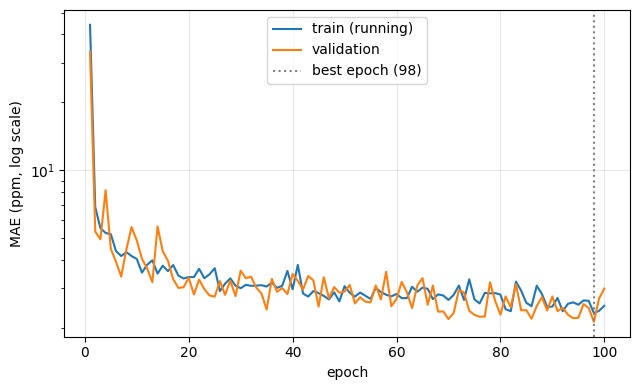

Loaded best checkpoint.


In [ ]:
# Learning curves: the single most useful diagnostic plot in machine learning.
plt.figure(figsize=(6.5, 4))
plt.plot(history["epoch"], history["train_mae"], label="train (running)")
plt.plot(history["epoch"], history["val_mae"], label="validation")
plt.axvline(best_epoch, color="gray", ls=":", label=f"best epoch ({best_epoch})")
plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MAE (ppm, log scale)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# Reload the best weights; everything below uses the best model, not the last one.
if os.path.exists(CHECKPOINT):
    model.load_state_dict(torch.load(CHECKPOINT, map_location=device))
    print("Loaded best checkpoint.")

**How to read the curves.**

* Both curves falling: the model is still learning.
* Training MAE keeps falling but validation MAE flattens or rises: **overfitting**. The best-epoch line shows where validation was best.
* Both flat and high: the model is too small, the learning rate is off, or the features lack the needed information (**underfitting**).

**6.4 Optional: keep the checkpoint.** Colab runtimes are temporary. Tick the box to copy the best weights to Google Drive so you can reload them later without retraining (`model.load_state_dict(torch.load(path))`).

In [ ]:
#@title 6.4 (optional) Save the best checkpoint to Google Drive { display-mode: "form" }
save_checkpoint_to_drive = False #@param {type:"boolean"}
if save_checkpoint_to_drive:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs("/content/drive/MyDrive/GCN_NMR", exist_ok=True)
    shutil.copy(CHECKPOINT, "/content/drive/MyDrive/GCN_NMR/")
    print("Copied", CHECKPOINT, "to MyDrive/GCN_NMR/")

## 7. Evaluation on the test set

Now, **once**, we measure performance on the test molecules that were never used for training or for choosing the epoch.

For every carbon in the test set we collect the prediction and the experimental value, and compute:

* **MAE**: mean |error|, the typical error in ppm.
* **RMSE**: root-mean-square error; penalises large errors more than MAE.
* **Median absolute error**: robust to a few terrible predictions.
* **R²**: fraction of the variance in the shifts explained by the model (1 = perfect, 0 = no better than predicting the mean).
* **Baseline**: the MAE of always predicting the *training-set mean shift*. A model must beat this to have learned anything.

**What to expect.** The original tutorial reported about **2.4 ppm** MAE after fewer than 100 epochs and **1.3–1.4 ppm** for a larger, carefully tuned network. Jonas & Kuhn report about 1.4 ppm for ¹³C. Your number will differ: this notebook uses a validation split, fixes a feature bug (see §9) and runs on different hardware.

In [ ]:
@torch.no_grad()
def predict_loader(model, loader):
    """Predict every labelled carbon in `loader`. Returns a DataFrame with one row per carbon."""
    model.eval()                                            # BatchNorm must use running averages
    frames = []
    for batch in loader:
        batch = batch.to(device)
        pred = model(batch.x, batch.edge_index, batch.batch)
        mask = batch.y != MISSING
        # index of each atom *within its own molecule*: global position minus the molecule's start
        local_idx = torch.arange(batch.num_nodes, device=device) - batch.ptr[batch.batch]
        frames.append(pd.DataFrame({
            "mol_id":   batch.mol_id[batch.batch][mask].cpu().numpy(),   # row in the original table
            "atom_idx": local_idx[mask].cpu().numpy(),
            "y_true":   batch.y[mask].cpu().numpy(),
            "y_pred":   pred[mask].cpu().numpy(),
        }))
    df = pd.concat(frames, ignore_index=True)
    df["error"] = df["y_pred"] - df["y_true"]
    return df


def summarise(df, label):
    err = df["error"].to_numpy()
    ss_res = float((err ** 2).sum())
    ss_tot = float(((df["y_true"] - df["y_true"].mean()) ** 2).sum())
    return {"set": label, "carbons": len(df),
            "MAE (ppm)": np.abs(err).mean(),
            "RMSE (ppm)": math.sqrt((err ** 2).mean()),
            "median |err| (ppm)": float(np.median(np.abs(err))),
            "R2": 1 - ss_res / ss_tot}


test_pred = predict_loader(model, test_loader)
val_pred  = predict_loader(model, val_loader)

# Baseline: always predict the mean shift of the training molecules.
train_mean = float(np.mean([g.y[g.y != MISSING].mean().item() for g in train_graphs]))
baseline = test_pred.assign(y_pred=train_mean)
baseline["error"] = baseline["y_pred"] - baseline["y_true"]

pd.DataFrame([summarise(val_pred, "validation"),
              summarise(test_pred, "TEST"),
              summarise(baseline, "baseline: predict the mean")]).round(3)

,set,carbons,MAE (ppm),RMSE (ppm),median |err| (ppm),R2
0,validation,17560,2.132,3.189,1.449,0.996
1,TEST,44560,2.133,3.288,1.440,0.996
2,baseline: predict the mean,44560,46.310,51.207,41.780,-0.003


Two plots summarise the whole test set. In the **parity plot** each dot is one carbon (experiment on x, prediction on y). In the **error histogram** we want a narrow peak centred on zero; a shifted peak would mean a systematic bias.

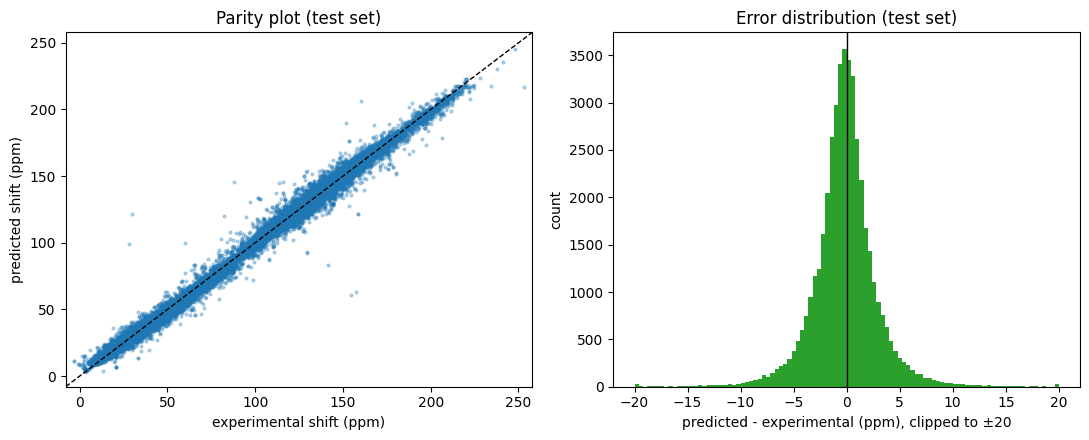

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

# Parity plot: a perfect model puts every point on the diagonal.
lims = [min(test_pred.y_true.min(), test_pred.y_pred.min()) - 5,
        max(test_pred.y_true.max(), test_pred.y_pred.max()) + 5]
ax[0].scatter(test_pred.y_true, test_pred.y_pred, s=4, alpha=0.3)
ax[0].plot(lims, lims, "k--", lw=1)
ax[0].set(xlim=lims, ylim=lims, xlabel="experimental shift (ppm)", ylabel="predicted shift (ppm)",
          title="Parity plot (test set)")

# Error histogram: should be centred on 0 and narrow.
clip = test_pred.error.clip(-20, 20)
ax[1].hist(clip, bins=100, color="tab:green")
ax[1].axvline(0, color="k", lw=1)
ax[1].set(xlabel="predicted - experimental (ppm), clipped to ±20", ylabel="count",
          title="Error distribution (test set)")
plt.tight_layout(); plt.show()

### 7.1 Where does the model fail?

Averages hide the interesting cases. Here are the **test molecules with the largest mean error**. Each carbon is labelled `predicted | experimental`. Typical culprits: unusual functional groups that are rare in the training data, strained or charged systems, possible mis-assignments in the database itself, and effects the 2-D graph cannot see (solvent, stereochemistry, conformation).

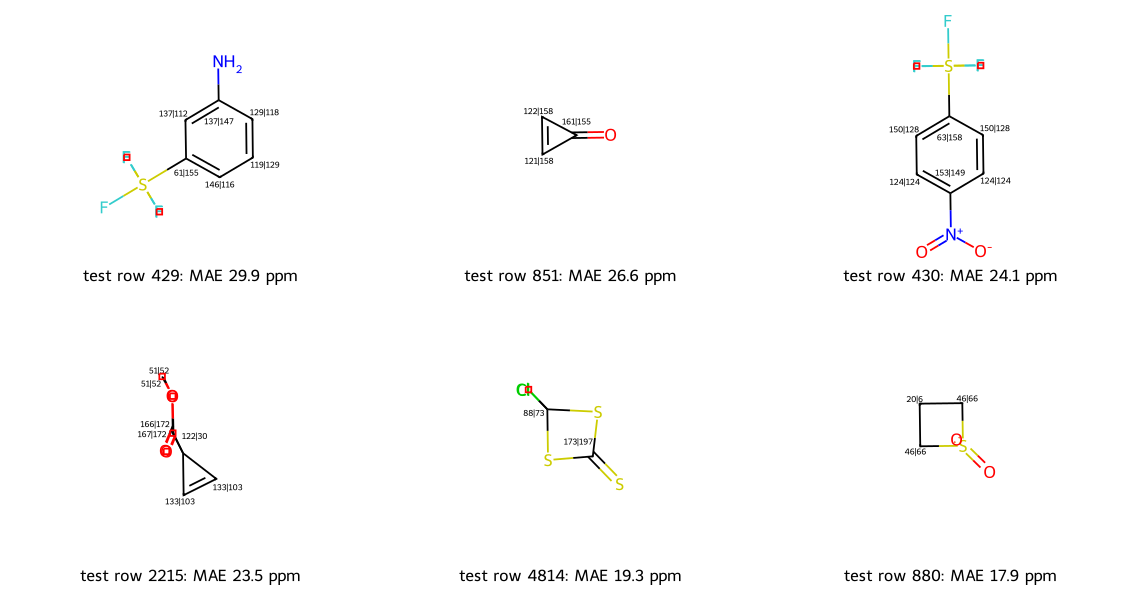

In [ ]:
per_mol_mae = test_pred.groupby("mol_id")["error"].apply(lambda e: e.abs().mean()).sort_values(ascending=False)

worst_mols, worst_legends = [], []
for mol_id, mae in per_mol_mae.head(6).items():
    rows = test_pred[test_pred.mol_id == mol_id]
    notes = {int(r.atom_idx): f"{r.y_pred:.0f}|{r.y_true:.0f}" for r in rows.itertuples()}
    worst_mols.append(draw_with_notes(test_mols[mol_id], notes))
    worst_legends.append(f"test row {mol_id}: MAE {mae:.1f} ppm")

Draw.MolsToGridImage(worst_mols, molsPerRow=3, subImgSize=(380, 300), legends=worst_legends)

### 7.2 One test molecule in detail

Pick any `choice` (a row number in the *test table*). The cell prints a table of per-carbon predictions and draws the structure with `predicted | experimental` labels. If the molecule was filtered out in §4 (e.g. incomplete spectrum), the cell tells you and you can pick another.

 atom_idx     y_pred     y_true  error
        0 150.500000 148.699997    1.8
        1 148.899994 147.199997    1.7
        2 110.599998 111.099998   -0.5
        3 111.800003 111.800003    0.0
        4 134.300003 134.300003   -0.0
        5 121.099998 120.199997    0.9
        6  36.099998  38.200001   -2.1
        7  35.700001  37.400002   -1.7
        8 142.600006 143.399994   -0.8
        9 119.400002 111.199997    8.2
       10 128.800003 129.199997   -0.4
       11 111.699997 120.900002   -9.2
       12 160.899994 159.600006    1.3
       13 113.400002 114.199997   -0.8
       17  55.400002  55.799999   -0.4
       18  55.299999  55.900002   -0.6
       19  54.200001  55.099998   -0.9

MAE for this molecule: 1.84 ppm


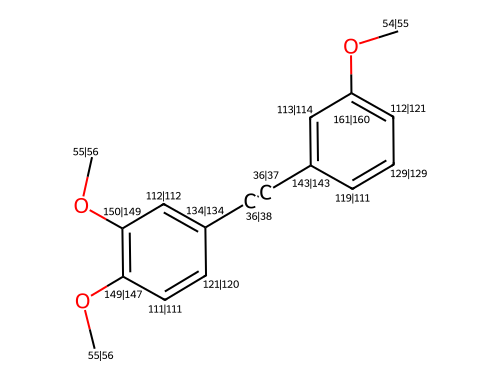

In [ ]:
choice = 20   # <- change me: a row number of the test table

rows = test_pred[test_pred.mol_id == choice]
if rows.empty:
    available = sorted(test_pred.mol_id.unique())
    print(f"Test row {choice} was filtered out or has no labelled carbons. Try one of: {available[:15]} ...")
else:
    print(rows[["atom_idx", "y_pred", "y_true", "error"]].round(1).to_string(index=False))
    print(f"\nMAE for this molecule: {rows.error.abs().mean():.2f} ppm")
    notes = {int(r.atom_idx): f"{r.y_pred:.0f}|{r.y_true:.0f}" for r in rows.itertuples()}
    display(Draw.MolToImage(draw_with_notes(test_mols[choice], notes), size=(500, 380)))

## 8. Bonus: predict the spectrum of *your* molecule

Think of an organic molecule, look up its **SMILES** string (e.g. on PubChem or Wikipedia), paste it below, and run the cell. The pipeline is:

`SMILES → RDKit molecule → add hydrogens → generate a 3-D conformer → features → model → ¹³C shifts`

Notes and caveats:

* The model knows only **C, H, N, O, F, P, S, Cl**. Molecules with other elements (Br, I, Si, B, metals ...) are rejected.
* The 3-D conformer is generated randomly (we fix the random seed for repeatability). Because raw x/y/z coordinates are part of our features, a *different* conformer can change the prediction. That is a weakness of this feature set; see Exercise 4.
* The model was trained on neutral, mostly small organic molecules; predictions for molecules unlike the training data are less trustworthy.

Predicted 13C NMR shifts for Caffeine:
 atom_idx  predicted_ppm
        0           37.9
        2          141.1
        4          148.5
        5          107.6
        6          157.5
        9          150.2
       12           37.5
       13           34.7


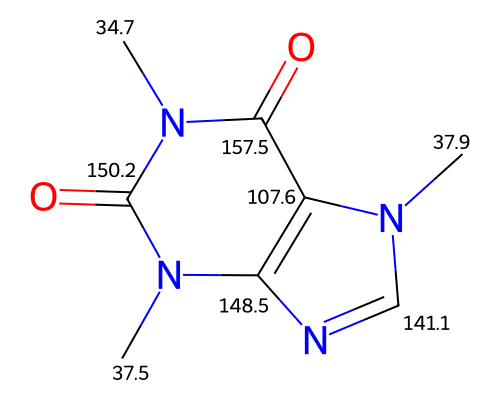

In [ ]:
#@title 8.1 Enter your molecule { display-mode: "form" }
Your_Organic_Molecule_SMILES = "CN1C=NC2=C1C(=O)N(C(=O)N2C)C" #@param {type:"string"}
Compound_Name = "Caffeine" #@param {type:"string"}
Format = "Show shifts" #@param ["Show shifts", "Show shifts + atom index"]
conformer_seed = 42 #@param {type:"integer"}


@torch.no_grad()
def predict_from_smiles(smiles, seed=42):
    """SMILES -> (molecule with explicit H, DataFrame of predicted 13C shifts)."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"RDKit could not parse the SMILES string: {smiles!r}")
    mol = Chem.AddHs(mol)                                       # the model expects explicit hydrogens
    if AllChem.EmbedMolecule(mol, randomSeed=seed) < 0:         # 3-D conformer for x, y, z
        raise RuntimeError("Could not generate a 3-D conformer for this molecule.")

    x, edge_index = get_one_model_input(mol)
    if x is None:
        raise ValueError("Cannot featurise this molecule. Supported elements: " + ", ".join(ELEMENTS))

    model.eval()
    pred = model(x.to(device), edge_index.to(device)).cpu()     # prediction for every atom
    carbon_idx = (x[:, 0] == 6).nonzero().flatten().tolist()    # keep carbons only
    table = pd.DataFrame({"atom_idx": carbon_idx,
                          "predicted_ppm": [round(pred[i].item(), 1) for i in carbon_idx]})
    return mol, table


my_mol, my_table = predict_from_smiles(Your_Organic_Molecule_SMILES, conformer_seed)
print(f"Predicted 13C NMR shifts for {Compound_Name}:")
print(my_table.to_string(index=False))

with_index = Format.endswith("index")
notes = {int(r.atom_idx): (f"#{int(r.atom_idx)} {r.predicted_ppm}" if with_index else f"{r.predicted_ppm}")
         for r in my_table.itertuples()}
Draw.MolToImage(draw_with_notes(my_mol, notes), size=(500, 400))

## 9. Wrap-up

### What you did

1. Represented molecules as graphs: **47 features per atom + a bidirectional bond list**.
2. Batched many molecules into one disconnected graph with PyTorch Geometric.
3. Verified a **graph convolution** by hand, then trained a **6-layer residual GCN** with a **masked MSE loss**.
4. Used a **validation set** to select the best epoch and a held-out **test set** for the final evaluation, with a **baseline**, **parity plot** and **error analysis**.
5. Predicted a spectrum straight from a **SMILES** string.

### Exercises

1. **Depth ablation.** Change `n_graph_blocks` in `GNN` (0, 1, 2, 5, 8). How does the test MAE change? Relate this to the receptive field (§0.3). What might go wrong with very many layers? *(Hint: "over-smoothing".)*
2. **Swap the layer.** In `ResGraph` replace `GCNConv` by `GraphConv` or `GATConv` (both from `torch_geometric.nn`). Do the results change?
3. **Feature ablation.** Remove feature groups (e.g. the Gasteiger charge, the ring flags, the one-hots) by slicing columns of `x`, and retrain with a reduced `in_feats`. Which groups matter most? Use short runs (e.g. 20 epochs) and compare on the validation set.
4. **Rotation test.** Take one test molecule, rotate its conformer (e.g. with `rdkit.Chem.rdMolTransforms` or by editing coordinates), featurise again and compare the predictions. What do you observe, and what does it say about including raw x, y, z as features? Then retrain *without* x, y, z (3 fewer features) and repeat.
5. **Conformers.** In §8, vary `conformer_seed` for a flexible molecule. How large is the spread of predictions?
6. **Incomplete spectra.** Set `REQUIRE_COMPLETE_SPECTRA = False` to also train on partially assigned spectra (this is where the masking really matters). Does the data gain help?
7. **Uncertainty.** The key contribution of Jonas & Kuhn was predicting *uncertainty*. Train 5 models with different seeds and use the spread of their predictions as a crude uncertainty estimate. Do large spreads correlate with large errors?
8. **Hydrogens.** The same pipeline can predict ¹H shifts. What would you change in the targets and in the mask?

### Limitations to keep in mind

* **Data.** Experimental shifts come from a community database; assignments can be wrong, and solvent and temperature are ignored.
* **Features.** Raw coordinates are not rotation-invariant; stereochemistry and conformation are only weakly represented; no bond features beyond "which bond types an atom has".
* **Domain.** Only 8 elements and mostly small, neutral organic molecules.
* **Point estimates.** The model gives a single number with no confidence interval.
* **Reproducibility.** Seeds are fixed, but GPU arithmetic is not bit-for-bit deterministic.


### Troubleshooting

| Symptom | Likely cause and fix |
|---|---|
| `ModuleNotFoundError` for `rdkit` / `torch_geometric` right after the install cell | Do **Runtime → Restart session**, then continue from §1.2 (no need to reinstall). |
| Device shows **CPU** | Runtime → Change runtime type → choose a GPU, then re-run from §1.2. |
| Loading the pickle fails with a pandas- or RDKit-related error | The file was written with much older library versions. Try `%pip install "pandas<2"` (and, if needed, an older `rdkit`), restart the session, and re-run §1.2 onwards. |
| `FileNotFoundError` in §2.1 | Check the file name and, for Drive, the `drive_folder` path. |
| Many molecules reported as "could not featurise" | They contain unsupported elements, lack a 3-D conformer, or RDKit produced NaN partial charges. |
| `CUDA out of memory` | Lower `BATCH_SIZE` (and/or `HIDDEN`) in §1.3 and re-run §4 onwards. |
| `Expected all tensors to be on the same device` | The model or a tensor was not moved with `.to(device)`; re-run §1.2 and §5.2. |
| Validation MAE is much worse than training MAE | Overfitting: fewer epochs (use the best checkpoint), a smaller model, or more regularisation. |
| Session disconnected and everything is gone | Colab runtimes are temporary; save checkpoints to Drive (§6.2) and keep the dataset on Drive (§2.1). |

### Change log: what was updated relative to the 2021 notebook

| Area | Original | Revised | Why |
|---|---|---|---|
| Installation | `kora`, `torch-scatter`/`torch-sparse` wheels for torch 1.7 / CUDA 10.1, `mendeleev==0.3.1` | `%pip install rdkit torch_geometric` | Old wheels no longer exist; `GCNConv` needs nothing else. |
| Imports | `torch_geometric.data.dataloader`, `torch_geometric.data.data.Data`, `MolDrawing`/`DrawingOptions`, `GetMorganFingerprintAsBitVect`, many unused imports | `torch_geometric.loader.DataLoader`, `torch_geometric.data.Data`, `IPythonConsole.drawOptions`; unused imports removed | Removed or deprecated in current PyG / RDKit. |
| Element properties | fetched with `mendeleev` (slow API calls) | small lookup table for the 8 supported elements | Speed, no API-version dependence. Values may differ from `mendeleev`'s in the last digits. |
| Data access | hard-coded personal Drive path (`/content/mydir/MyDrive/Victor/...`) and a separate "local computer" cell | one cell: upload, Drive, or URL; graceful errors | Works for anyone. |
| **One-hot features (bug fix)** | `valence_map[v] = 1` and `hybrid_map[h] = 1` overwrote a dictionary entry instead of setting `array[i] = 1`, so the valence and hybridisation one-hot columns were **always zero**. The hybridisation dictionary was also keyed by hard-coded integers rather than RDKit's enum values. | filled correctly using explicit RDKit enums | Those 12 columns now carry information. **Results will differ from the original numbers.** |
| **Test-time BatchNorm (bug fix)** | the validation/test pass during training ran while the model was still in `train()` mode | `model.train(training)` / `model.eval()` inside `run_epoch` | In train mode BatchNorm used test-batch statistics and updated its running averages with test data. |
| Model selection | test error watched during training | separate molecule-grouped validation set + best-epoch checkpoint | Avoids test-set leakage. |
| Targets | python lists of lists flattened every step, `-1000` mask built on CPU | `y` stored as a tensor; mask computed on-device; per-atom Python loops removed | Much faster, clearer. |
| Training loop | 500 epochs, per-atom `.item()` loops, unused `epsilon` | `EPOCHS` setting, vectorised metrics, progress bar, learning curves, interrupt-safe | Practical in Colab. |
| Evaluation | one molecule inspected by eye | full test metrics, baseline, parity plot, error histogram, worst molecules | Shows how good the model really is. |
| Bonus cell | could crash for unsupported elements or failed 3-D embedding | validated input, clear error messages, per-atom table, selectable conformer seed | Robustness. |
| Text | some imprecise statements (e.g. BatchNorm "same as a linear layer", group-norm description) | corrected, with background section, glossary, shape/sanity checks and exercises | Accuracy and pedagogy. |

### References

* E. Jonas, S. Kuhn. *Rapid prediction of NMR spectral properties with quantified uncertainty.* J. Cheminform. **11**, 50 (2019). doi:10.1186/s13321-019-0374-3
* T. N. Kipf, M. Welling. *Semi-supervised classification with graph convolutional networks.* ICLR 2017. arXiv:1609.02907
* M. Fey, J. E. Lenssen. *Fast graph representation learning with PyTorch Geometric.* ICLR Workshop on Representation Learning on Graphs and Manifolds, 2019.
* K. He, X. Zhang, S. Ren, J. Sun. *Deep residual learning for image recognition.* CVPR 2016.
* S. Ioffe, C. Szegedy. *Batch normalization: accelerating deep network training by reducing internal covariate shift.* ICML 2015.
* RDKit: open-source cheminformatics, https://www.rdkit.org
* NMRShiftDB: https://nmrshiftdb.nmr.uni-koeln.de